# Order-parameter composites: unsupervised $q$ tracking a physical $Q$

The paper's section-4 figure (iteration 2, 2026-10-21). The left column is the main case, 2:1 cross-frequency locking between resonant oscillator communities (the M24 varying-sensor-noise arm). The right column stacks three further systems: the measured electronic oscillators (ER sweep), the fine Stuart–Landau locked-to-unsteady sweep, and the collective period-two 2D coupled map lattice. In every panel $q$ is the centred PC1 of SPI–SPI $z$, fitted without $Q$, control or nuisance labels; $Q$ is computed independently from the physics. Code: [`composite_figures.py`](../composite_figures.py) (registry `SYSTEMS`). Every panel is also exported on its own (SVG, PDF, 600-dpi PNG) under `results/order-parameter-inference/composites-261021/panels/<system>/`. Text is typeset by LaTeX in Computer Modern when `latex` and `dvipng` are available, with a native Computer Modern-math fallback otherwise.

**Reading the figure.** (a) Control against $Q$ (black, left axis) and $q$ (teal, right axis). Thick lines are means over held instances; faint lines are the individual instances. Each inset is a robust-scaled MTS heatmap (boxed) of a short window of one recording, with a physical glyph of the same recording above it and a leader line to its control on $Q$. (b) $Q$ against mean-$|r|$ and mean-MPI PC1, without ticks. (c) $z_{ab}$ for named feature pairs against control on a fixed $[-1,1]$ range, with 10–90% bands; triangles mark the snapshot controls. (d) Edge planes: SPI $a$ against SPI $b$ across all $M(M-1)$ ordered channel pairs of the snapshot recordings, in the same columns as (c). (e–g) Compact panels: heatmaps with glyphs above the $Q$/$q$ curves; the subtitle gives $|\rho_s|$ with $Q$ for $q$ and both baselines.

**Faint lines.** In Stuart–Landau, Kuramoto and CML2D an instance (seed) is paired across controls, so a faint line follows one population or start through the sweep. In locking every control–seed pair is an independent realisation; lines join realisations with the same seed index and only display spread. The hardware has one recording per setting.

**What is claimed.** $q$ tracks $Q$ across controls. This is not a calibration of $Q$, not a mechanism, and not superiority over simple statistics: in hardware, Stuart–Landau and CML2D the baselines track $Q$ as well or better by rank. Feature names follow what calibration supports.

**Snapshots** follow fixed rules, never $Q$ or $q$. Locking: the held recordings with sensor noise nearest $\eta=.6$ at $\gamma=0,.10,.14$, the only held recordings whose MPIs are local. Hardware: ER settings 0, 23 (the last setting with phase slips) and 87. Stuart–Landau: instance 0 at $\gamma=.68$, $.725$ (the steepest interval) and $.77$. Kuramoto: the first held seed. CML2D: the fixed pilot seed of the three-systems figure; the curves are the 32-seed confirmation bank.

**Glyphs (defaults).** Locking: the wrapped slow–fast phase $\Phi(t)=\arg Z_B-\arg Z_{A,2}$, the quantity whose time-averaged phasor on a later window defines $Q$. Hardware: the wrapped carrier phase of the four late-locking channels (12/18/21/24) relative to the most coherent core channel. Stuart–Landau and Kuramoto: the global order-parameter magnitude $R(t)$. CML2D: the whole 256 × 256 lattice (archived state after the reference window), with the 32 observed sites circled. Every glyph is regenerated from the archived generator and checked against the archived input. Heatmaps show 80 samples (locking), 0.08 s (hardware), 150 and 200 samples (Stuart–Landau, Kuramoto) and 40 steps (CML2D), so individual oscillations are resolved.

In [1]:
import io
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'src/mtsspi/spi_spi_contract.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, display
from research.inference.benchmarks import composite_figures as cf
pd.set_option('display.width', 220)

def show(path, width=1500):
    """Display a downsampled preview; the saved PNG/SVG/PDF files are full resolution."""
    image = PILImage.open(path)
    image.thumbnail((width, 10*width))
    buffer = io.BytesIO(); image.save(buffer, format='PNG')
    display(Image(data=buffer.getvalue()))

systems = {name: cf.load(name) for name in ('locking', 'hardware', 'stuart-landau', 'kuramoto', 'cml2d')}
locking, hardware, sl, kuramoto, cml = systems.values()
pd.DataFrame({name: {k: d.metrics[k] for k in ('q', 'mean-|r|', 'mean-MPI')} for name, d in systems.items()}).round(3)

,locking,hardware,stuart-landau,kuramoto,cml2d
q,0.871,0.892,0.886,0.826,0.883
mean-|r|,0.032,0.950,0.915,0.998,0.966
mean-MPI,0.020,0.982,0.883,0.994,0.973


## Feature contract and replay checks

$z$ must use all $M(M-1)$ ordered off-diagonal entries (`unified_ordered_v3`). For each locking and hardware snapshot recording, the whole stored $z$ row (41,616 coordinates) is rebuilt from the archived MPIs with the library builder and compared with the bank; each displayed edge profile is replayed. The legacy upper-symmetrised value is listed alongside: it differs for the directed LCSS × TE pair, so the check can tell the contracts apart. The locking replay reproduces the archived noisy observations exactly. Stuart–Landau and Kuramoto glyphs come from regenerated trajectories that match the archived inputs (to float32 precision for Stuart–Landau). CML2D $q$ values are replayed from the frozen model by `three_systems.load_cml`.

In [2]:
checks = pd.DataFrame([dict(system=name, record=c['row_id'], **{k: v for k, v in c.items() if k != 'row_id'})
                       for name, d in systems.items() for c in d.provenance.get('snapshot_checks', [])])
checks['row_contract'] = checks.row_contract.map(lambda c: c if isinstance(c, float) else f"passes={c['passes']}, max error {c['max_error']:.1e}")
display(checks)
edges = pd.DataFrame([dict(system=d.spec.name, **r) for d in (locking, hardware) for r in d.provenance['edge_receipts']])
edges.assign(feature=edges.feature.str.replace('\n', ' ', regex=False)).round(4)

,system,record,observation_replay_max_error,row_contract,regeneration_max_error
0,locking,xfreq21-random-noise-g000-s209,0.0,"passes=True, max error 8.7e-17",NaN
1,locking,xfreq21-random-noise-g100-s212,0.0,"passes=True, max error 7.2e-17",NaN
2,locking,xfreq21-random-noise-g140-s215,0.0,"passes=True, max error 7.8e-17",NaN
3,hardware,r17451096-s000-t5000,NaN,"passes=True, max error 0.0e+00",NaN
4,hardware,r17451096-s023-t5000,NaN,"passes=True, max error 0.0e+00",NaN
5,hardware,r17451096-s087-t5000,NaN,"passes=True, max error 0.0e+00",NaN
6,stuart-landau,M32_T1000_I0_gamma0p680,NaN,NaN,2.980128e-08
7,stuart-landau,M32_T1000_I0_gamma0p725,NaN,NaN,2.979974e-08
8,stuart-landau,M32_T1000_I0_gamma0p770,NaN,NaN,2.980179e-08
9,kuramoto,kuramoto-k0.6250-s260916009-m32-t1000,NaN,NaN,0.000000e+00


,system,row_id,feature,z,stored,legacy_upper_symmetrized
0,locking,xfreq21-random-noise-g000-s209,LCSS $\times$ TE,0.6157,0.6157,0.7486
1,locking,xfreq21-random-noise-g000-s209,Johansen $\times$ Johansen,-0.4934,-0.4934,-0.4934
2,locking,xfreq21-random-noise-g000-s209,Pearson lag 2 $\times$ lag 20$^2$,0.3689,0.3689,0.3689
3,locking,xfreq21-random-noise-g100-s212,LCSS $\times$ TE,0.5140,0.5140,0.6350
4,locking,xfreq21-random-noise-g100-s212,Johansen $\times$ Johansen,-0.1522,-0.1522,-0.1522
5,locking,xfreq21-random-noise-g100-s212,Pearson lag 2 $\times$ lag 20$^2$,-0.7134,-0.7134,-0.7134
6,locking,xfreq21-random-noise-g140-s215,LCSS $\times$ TE,-0.0341,-0.0341,-0.0406
7,locking,xfreq21-random-noise-g140-s215,Johansen $\times$ Johansen,0.0797,0.0797,0.0797
8,locking,xfreq21-random-noise-g140-s215,Pearson lag 2 $\times$ lag 20$^2$,-0.7693,-0.7693,-0.7693
9,hardware,r17451096-s000-t5000,kernel SI $\times$ IDS,0.8962,0.8962,0.8962


## Composite, default: faint instance trajectories

Means are thick lines with small markers; the faint lines are individual held instances. The main headline grows to balance the column heights.

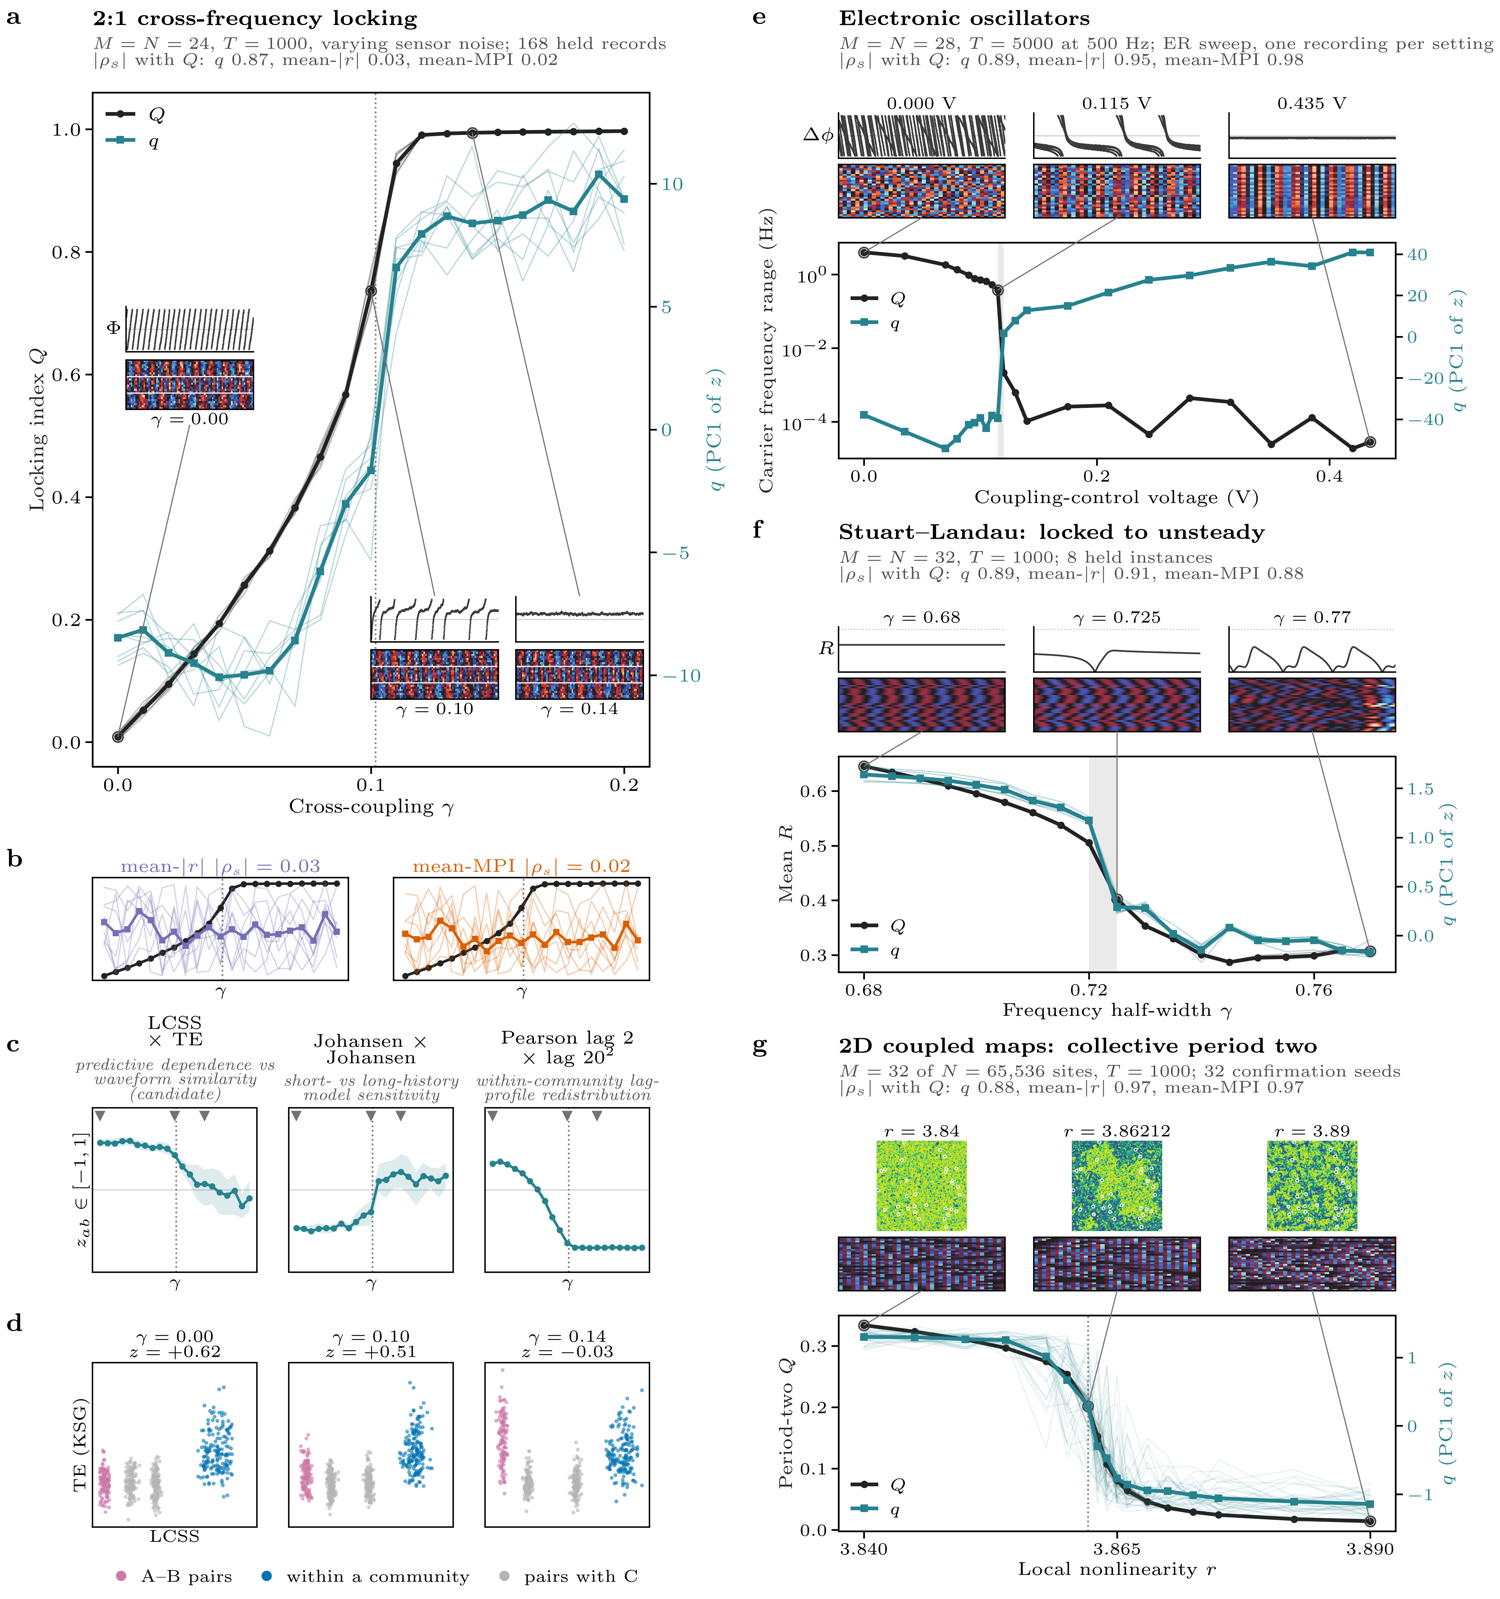

In [3]:
show(cf.save(cf.composite_stacked(locking, [hardware, sl, cml], spread='trajectories'), 'composite-stacked-trajectories'))

## The same with 10–90% bands instead of trajectories

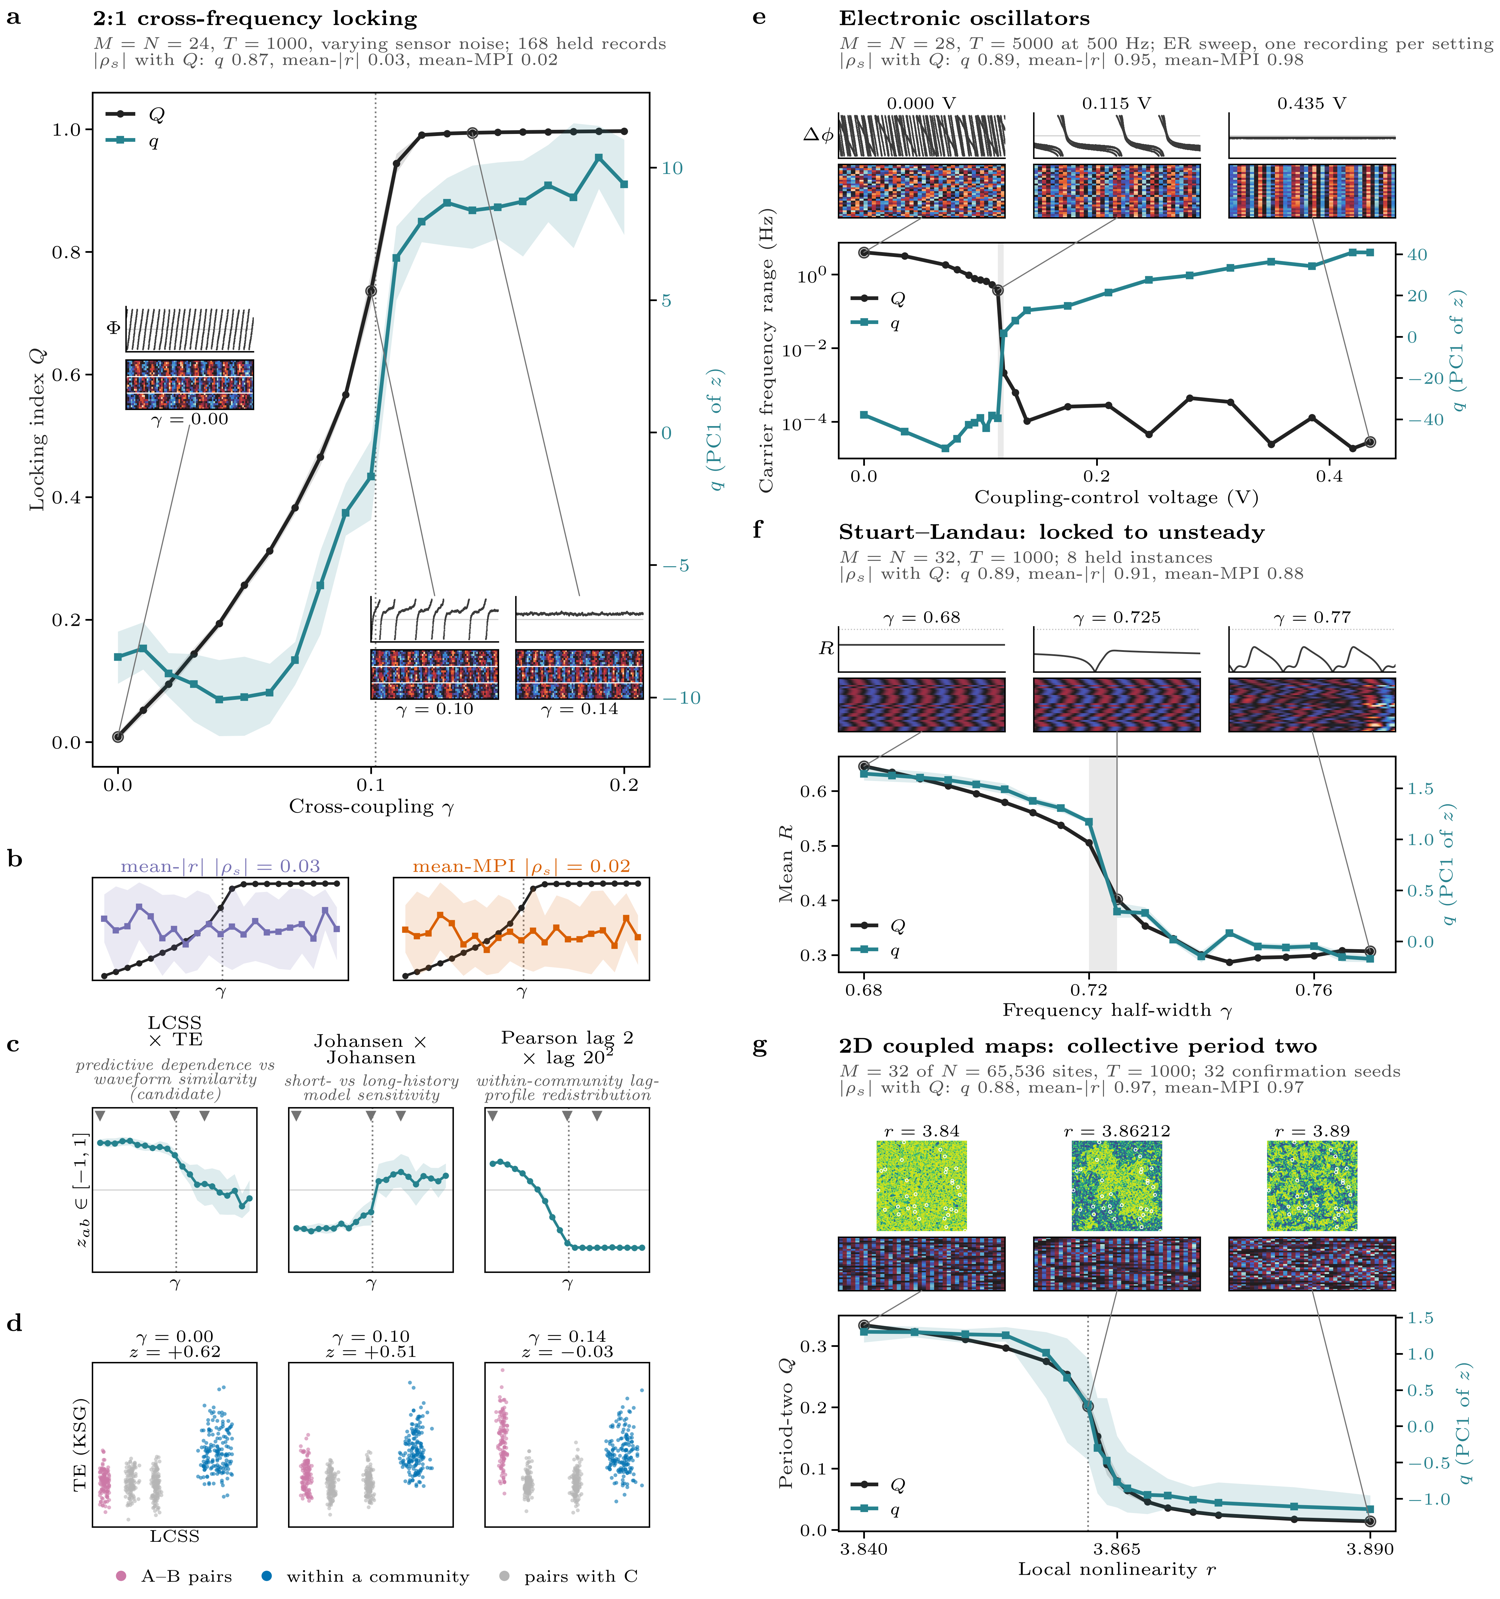

In [4]:
show(cf.save(cf.composite_stacked(locking, [hardware, sl, cml], spread='band'), 'composite-stacked-band'))

## Alternative middle panel: Kuramoto instead of Stuart–Landau

At $M=N=32$ the Kuramoto sweep is a gradual finite-size crossover with wide seed spread. Its $q$ is the weakest of the candidate systems (.83), the PC1-dominance screen was not met, and mean-$|r|$ (1.00) and mean-MPI (.99) are near-perfect, because synchronisation strength is the order parameter here. Stuart–Landau is recommended for the panel; see the notes below.

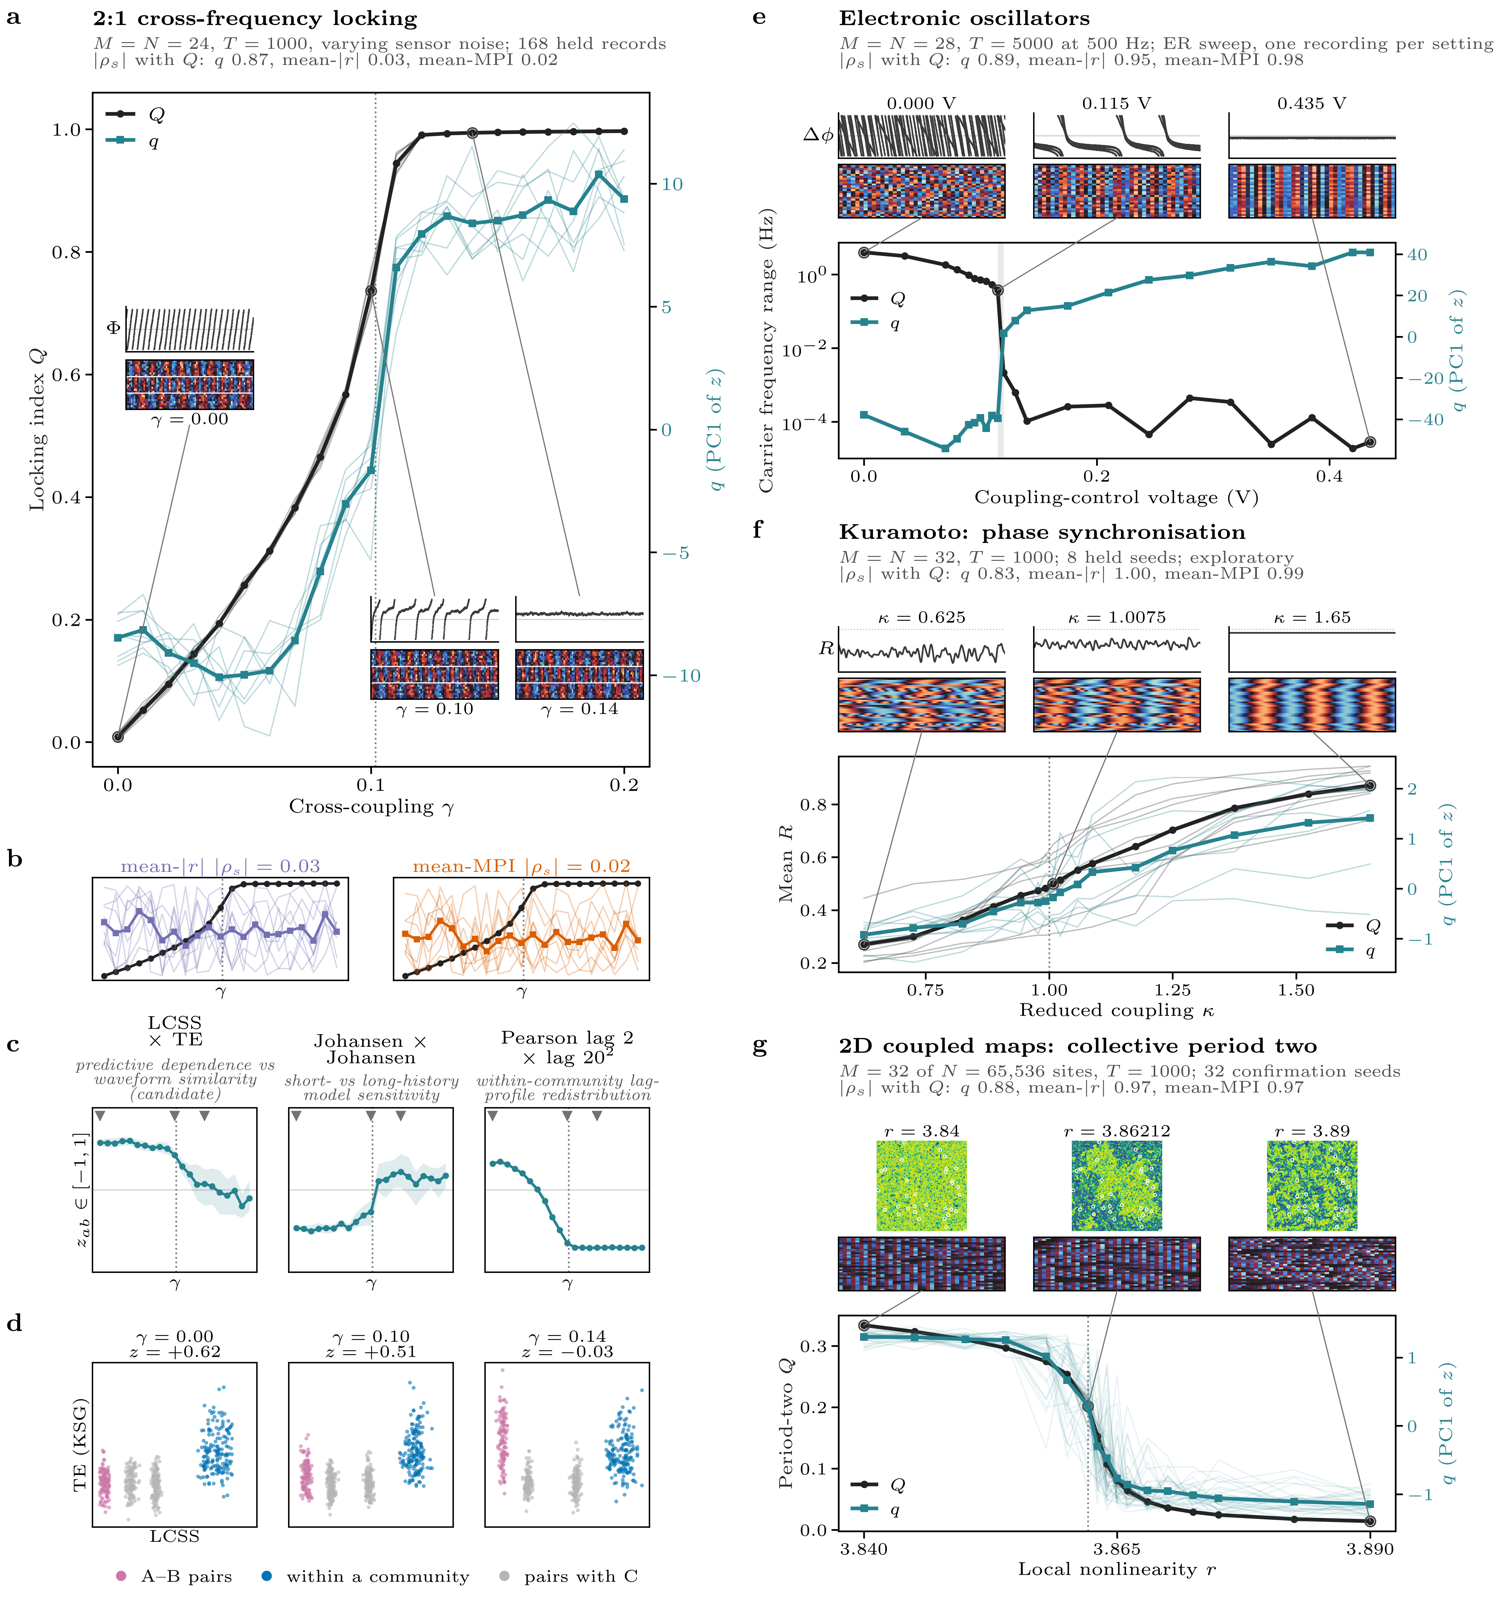

In [5]:
show(cf.save(cf.composite_stacked(locking, [hardware, kuramoto, cml], spread='trajectories'), 'composite-stacked-kuramoto'))

## Glyph options

All variants at the three snapshots. Locking: wrapped $\Phi$ (default), spiral ($\Phi$ as angle, time as radius), Lissajous ($\cos\arg Z_A$ against $\cos\arg Z_B$ over 60 time units). Hardware: wrapped late-channel phase (default), $R(t)$, phase raster. CML2D: lattice (default) or the global mean $\bar x(t)$ over 40 steps.

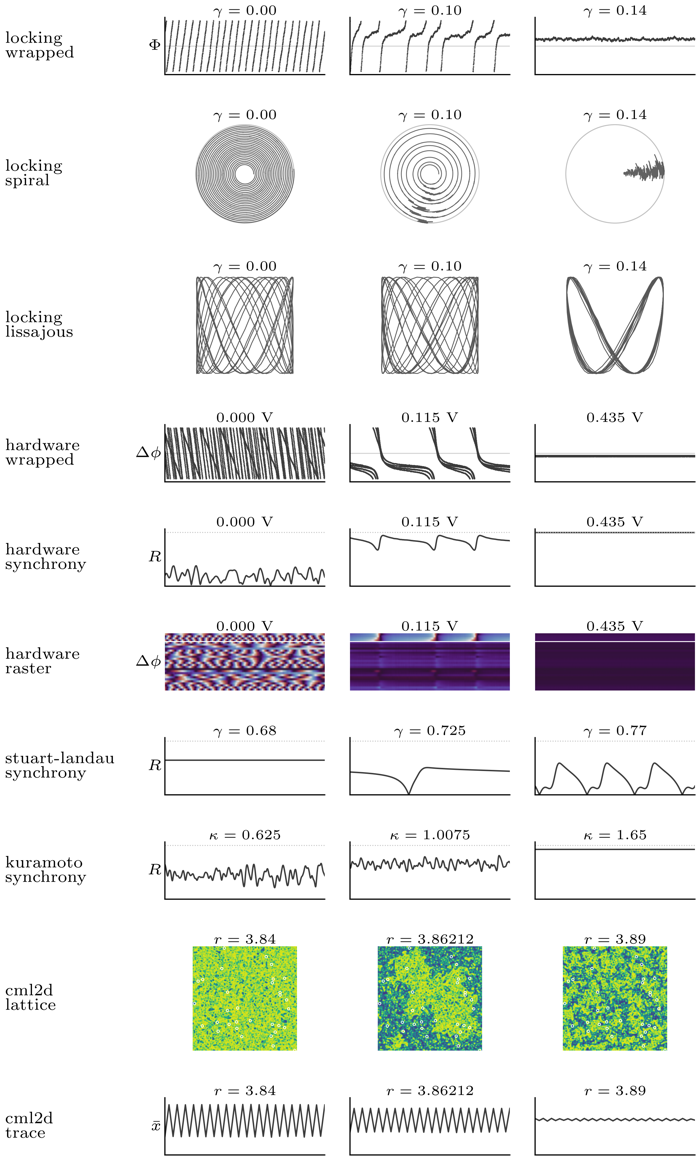

In [6]:
show(cf.save(cf.glyph_gallery([locking, hardware, sl, kuramoto, cml]), 'glyph-gallery'), width=700)

## Hardware: which physical quantity?

No universal order parameter is known for this apparatus. **Default:** the across-channel range of mean carrier frequency (log axis), whose collapse marks the cessation of phase slips at 23→24. **Alternatives:** mean carrier phase coherence $R_1$ (almost a monotone function of mean-$|r|$: rank correlation 1.00 on ER), the temporal SD of $R(t)$, or the fraction of frequency-locked channels (needs a threshold). With $R_1$, $q$'s rank association is similar, but $Q$ no longer shows the step that $q$ shows at slip cessation.

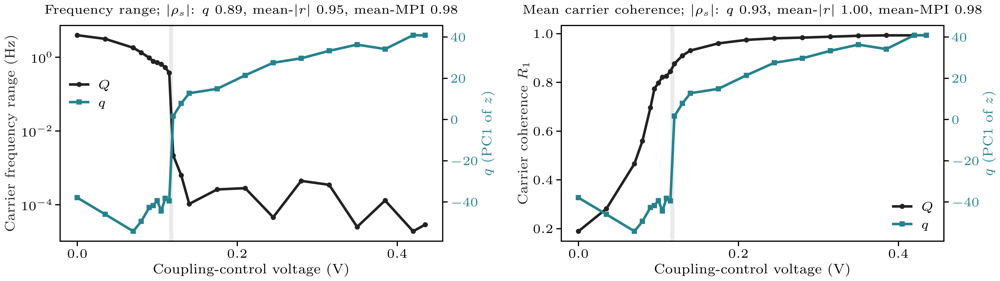

In [7]:
hardware_r1 = cf.load('hardware', Q_source='R1', Q_label='Carrier coherence $R_1$', Q_log=False, legend_loc='lower right')
show(cf.save(cf.compare_Q([hardware, hardware_r1], ['Frequency range', 'Mean carrier coherence']), 'hardware-Q-alternatives'), width=1000)

## Baselines: where simple statistics do as well

| system | $q$ | mean-$\lvert r\rvert$ | mean-MPI PC1 | rows |
|---|---|---|---|---|
| locking (held) | .871 | .032 | .020 | 168 |
| hardware ER, settings ≤ 87 | .892 | .950 | .982 | 22 |
| Stuart–Landau fine | .886 | .915 | .883 | 152 |
| Kuramoto, $M=N=32$ | .826 | .998 | .994 | 128 |
| CML2D confirmation | .883 | .966 | .973 | 544 |

Values are $|\rho_s|$ with $Q$. Only locking separates $q$ from both baselines; there the advantage is the ordering of variation under recording-specific noise, not information absent from the means (a supervised mean-vector readout reaches .900). In hardware the descriptive difference is localisation: $q$ crosses 43% of its displayed range over the slip-cessation interval 23→24, against 4.5% for mean-$|r|$ and 8.9% for mean-MPI ([baselines notebook](order-parameter-benchmarks-baselines.ipynb), section 7).

## Notes on the open questions

**Locking glyph: wrapped $\Phi$ is recommended.** It is the quantity $Q$ summarises ($Q=|\langle e^{i\Phi}\rangle|$ on a later window), so the glyph and the curve read as one object. It separates all three snapshots at a glance (continuous sawtooth, intermittent slips, flat band) and is scale-free. It also shares its visual language with the hardware glyph. The Lissajous is the most familiar picture of 2:1 locking, but over any fixed window it shows $\gamma=.10$ as a filled box like $\gamma=0$: it hides partial locking, exactly the transition state. It also depends on the window length and on the latent community mean fields rather than anything observed. The spiral encodes the same information as $\Phi$ but is denser and harder to read at inset size.

**Stuart–Landau over Kuramoto.** (i) The fine Stuart–Landau sweep is an independent confirmation: a frozen coordinate on 152 fresh rows, with every pre-outcome gate passed. The $M=N=32$ Kuramoto result is exploratory, since its PC1-dominance screen was not met. (ii) The Stuart–Landau transition is sharp, and $q$, mean $R$ and $\mathrm{sd}_t(R)$ have the same steepest interval (.720–.725). At $N=32$ Kuramoto is a gradual crossover, with $q$'s steepest interval adjacent to $Q$'s. (iii) Locked-to-unsteady changes the temporal character of the collective dynamics (constant against oscillating $R$), which fits the paper's character-first framing. Kuramoto synchronisation is strength itself, so mean-$|r|$ reaches .998 and $q$ (.826) looks weakest exactly where the framing says it should not be used. Kuramoto is probably the better-known model (inferred from its standing as the canonical synchronisation model, not measured), but recognition does not outweigh (i)–(iii). The Stuart–Landau path is Matthews & Strogatz's $K=.8$ cut, which keeps a classical reference.

**CML2D: what to show.** $Q$ is the period-two amplitude of the spatially averaged state on a disjoint future window. The default glyph is the whole lattice with the observed sites circled. It shows why $Q$ falls: one period-two phase fills the lattice at $r=3.84$, large domains of both phases coexist near $3.862$, and fine domains at $3.89$ average the collective oscillation away. It also shows that 32 scattered sensors sample this structure. Caveat: the lattice is the archived state after the reference window, not simultaneous with the observed window, and comes from the pilot seed. The alternative, the global mean $\bar x(t)$ (a large zigzag when ordered), is $Q$ itself and so partly redundant with the curve.

**Which systems have $M<32$?** Locking: $M=24$ (with an $M=48$ confirmation); hardware: $M=28$. Fine Stuart–Landau and full Kuramoto: $M=N=32$ only. The broad Stuart–Landau sweep ($\gamma=.55$–$1.25$) has separate $M=N=8,16,32$ systems at $T=100/500/1000$. CML2D has paired $M=16$ views at $T=500$ and $1000$ (288 rows each, nested sensors from the same masters, 9 old-grid controls) beside the primary $M=32$. All panels use $M=32$ or the full system.

## Export individual panels

In [8]:
written = {'locking': cf.export_panels(locking)}
for name in ('hardware', 'stuart-landau', 'kuramoto', 'cml2d'):
    written[name] = cf.export_panels(systems[name], stacked=True)
receipt = cf.receipt(list(systems.values()))
print({k: len(v) for k, v in written.items()}, 'panels (each as SVG, PDF and 600-dpi PNG) under', cf.OUT/'panels')
print('provenance:', receipt.relative_to(ROOT))

{'locking': 33, 'hardware': 17, 'stuart-landau': 9, 'kuramoto': 9, 'cml2d': 13} panels (each as SVG, PDF and 600-dpi PNG) under /Users/wedi0306/Code/mts-spi-study-cluster/results/order-parameter-inference/composites-261021/panels
provenance: results/order-parameter-inference/composites-261021/provenance.json


## Open choices

1. **Spread.** Faint trajectories (default) or bands.
2. **Glyphs.** Locking wrapped $\Phi$ (recommended), Lissajous or spiral; hardware wrapped phase, $R(t)$ or raster; CML2D lattice or $\bar x(t)$.
3. **Middle panel.** Stuart–Landau (recommended) or Kuramoto.
4. **Hardware $Q$ and range.** Frequency range on settings ≤ 87 (default), $R_1$, or the full 0–3.5 V sweep, where $q$ is non-monotone.
5. **Locking post-transition snapshot.** $\gamma=.14$ (local MPI) or $\gamma=.20$, which needs one held MPI fetched from Gadi.
6. **Heatmap window.** Currently 80/40/150/200/40 samples. Shorter still is possible, at the cost of showing fewer cycles of the slower components.